# Решение домашнего задания по генерации случайных чисел

### Импорты и настройка генераторов

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar
import itertools
import math

# Хороший генератор (LCG)
class LCG:
    def __init__(self, m=2**32, a=1103515245, c=12345, seed=1):
        self.m = m
        self.a = a
        self.c = c
        self.current = seed
    
    def __call__(self):
        self.current = (self.a * self.current + self.c) % self.m
        return self.current / self.m

rng = LCG()
samples = [rng() for _ in range(1000)]


### Задача 1*: Serial Test

In [35]:
def serial_test(sequence, k=10):
    x = sequence[:-1]
    y = sequence[1:]
    H, _, _ = np.histogram2d(x, y, bins=k, range=[[0,1],[0,1]])
    expected = len(x) / (k**2)
    chisq = np.sum((H - expected)**2 / expected)
    p_value = 1 - stats.chi2.cdf(chisq, k**2 - 1)
    return chisq, p_value

chisq1, p1 = serial_test(samples)
print(f'Serial Test: p-value = {p1:.4f}')


Serial Test: p-value = 0.5896


### Задача 2*: Permutation Test

In [36]:
def permutation_test(sequence, d=4):
    n = len(sequence)
    num_blocks = n // d
    blocks = [sequence[i*d : (i+1)*d] for i in range(num_blocks)]
    perms = list(itertools.permutations(range(d)))
    perm_map = {p: i for i, p in enumerate(perms)}
    counts = np.zeros(len(perms))
    
    for block in blocks:
        p_type = tuple(np.argsort(block))
        if p_type in perm_map:
            counts[perm_map[p_type]] += 1
    expected = num_blocks / len(perms)
    chisq = np.sum((counts - expected)**2 / expected)
    p_value = 1 - stats.chi2.cdf(chisq, len(perms) - 1)
    return chisq, p_value

chisq2, p2 = permutation_test(samples)
print(f'Permutation Test: p-value = {p2:.4f}')


Permutation Test: p-value = 0.4819


### Задача 3*: Сравнение rng и rng_bad

In [37]:
def rng_bad(m=2**31, a=65539, c=0):
    rng_bad.current = (a * rng_bad.current + c) % m
    return rng_bad.current / m
rng_bad.current = 1

def run_3d_test(gen_func, n=30000, k=15):
    # Генерируем новую последовательность внутри функции
    seq = [gen_func() for _ in range(n)]
    x = seq[:-2]
    y = seq[1:-1]
    z = seq[2:]
    H, _ = np.histogramdd(np.vstack([x, y, z]).T, bins=k, range=[[0,1]]*3)
    expected = len(x) / (k**3)
    chisq = np.sum((H - expected)**2 / expected)
    p_value = 1 - stats.chi2.cdf(chisq, k**3 - 1)
    return p_value

# Тестируем
rng_clean = LCG()
p_good = run_3d_test(rng_clean)

rng_dirty = LCG(m=2**31, a=65539, c=0)
p_bad = run_3d_test(rng_dirty)

print(f'3D Test RNG (Good): p-value = {p_good:.4f}')
print(f'3D Test RNG_BAD: p-value = {p_bad:.4f}')


3D Test RNG (Good): p-value = 0.9326
3D Test RNG_BAD: p-value = 0.0000


### Задача 4: Дискретное распределение

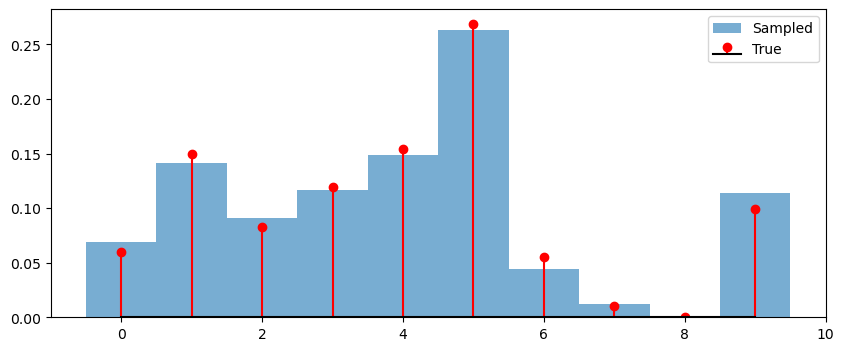

In [38]:
weights = np.array([0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2])
probs = weights / weights.sum()

# Оптимизация: сортировка вероятностей по убыванию
indices = np.argsort(probs)[::-1]
sorted_probs = probs[indices]
sorted_digits = np.arange(10)[indices]
cdf = np.cumsum(sorted_probs)

def generate_discrete(n=1000):
    u = np.random.rand(n)
    # Используем searchsorted для быстрого поиска
    idx = np.searchsorted(cdf, u)
    return sorted_digits[idx]

samples_d = generate_discrete(1000)
plt.figure(figsize=(10, 4))
plt.hist(samples_d, bins=np.arange(11)-0.5, density=True, alpha=0.6, label='Sampled')
plt.stem(range(10), probs, linefmt='r-', markerfmt='ro', basefmt='k-', label='True')
plt.legend()
plt.show()


### Задача 5: Экспоненциальное распределение

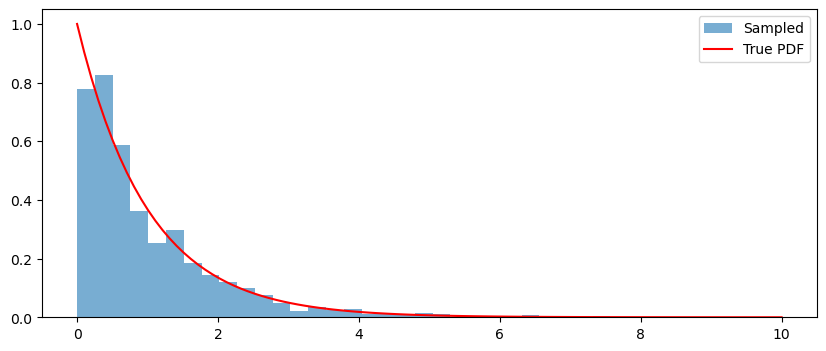

In [39]:
def generate_exp(n=1000, lam=1.0):
    u = np.random.rand(n)
    return -np.log(1 - u) / lam

samples_exp = generate_exp(1000)
x_grid = np.linspace(0, 10, 100)
pdf_exp = np.exp(-x_grid)

plt.figure(figsize=(10, 4))
plt.hist(samples_exp, bins=30, density=True, alpha=0.6, label='Sampled')
plt.plot(x_grid, pdf_exp, 'r-', label='True PDF')
plt.legend()
plt.show()


### Задача 6: Accept-Reject

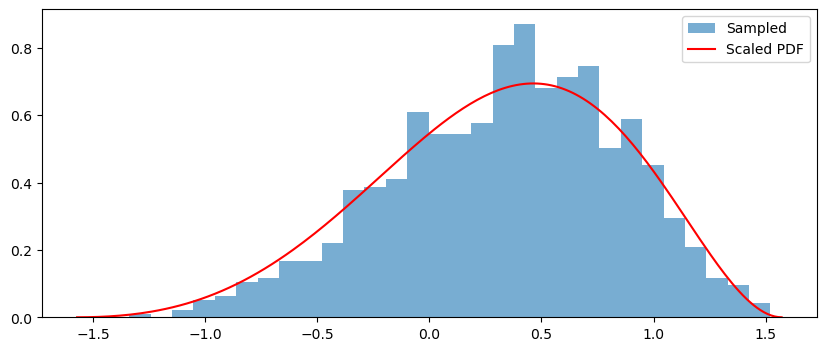

In [40]:
def target_func(x):
    return np.exp(x) * (np.cos(x)**2)

a, b = -np.pi/2, np.pi/2
# Максимум функции на отрезке
res = minimize_scalar(lambda x: -target_func(x), bounds=(a, b), method='bounded')
max_val = -res.fun

def generate_ar(n=1000):
    samples = []
    while len(samples) < n:
        x_prop = np.random.uniform(a, b)
        if np.random.rand() < target_func(x_prop) / max_val:
            samples.append(x_prop)
    return np.array(samples)

samples_ar = generate_ar(1000)
x_ar = np.linspace(a, b, 200)
norm_const = 1.58  # approximate normalization for plot
plt.figure(figsize=(10, 4))
plt.hist(samples_ar, bins=30, density=True, alpha=0.6, label='Sampled')
plt.plot(x_ar, target_func(x_ar)/np.mean(target_func(x_ar))*(1/(b-a)), 'r-', label='Scaled PDF')
plt.legend()
plt.show()


### Задача 7: Треугольник

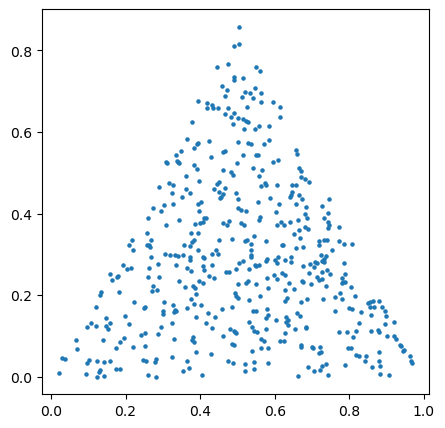

In [41]:
def generate_triangle(n=500):
    A, B, C = np.array([0,0]), np.array([1,0]), np.array([0.5, 0.866])
    r1 = np.random.rand(n, 1)
    r2 = np.random.rand(n, 1)
    points = (1 - np.sqrt(r1)) * A + (np.sqrt(r1) * (1 - r2)) * B + (np.sqrt(r1) * r2) * C
    return points

pts_tri = generate_triangle()
plt.figure(figsize=(5,5))
plt.scatter(pts_tri[:,0], pts_tri[:,1], s=5)
plt.show()


### Задача 8: Круг

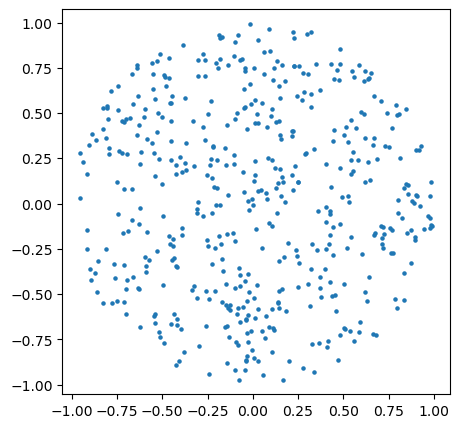

In [42]:
def generate_circle(n=500):
    u, v = np.random.rand(n), np.random.rand(n)
    r = np.sqrt(u)
    theta = 2 * np.pi * v
    return r * np.cos(theta), r * np.sin(theta)

xc, yc = generate_circle()
plt.figure(figsize=(5,5))
plt.scatter(xc, yc, s=5)
plt.axis('equal')
plt.show()


### Задача 9: Box-Muller и MVN

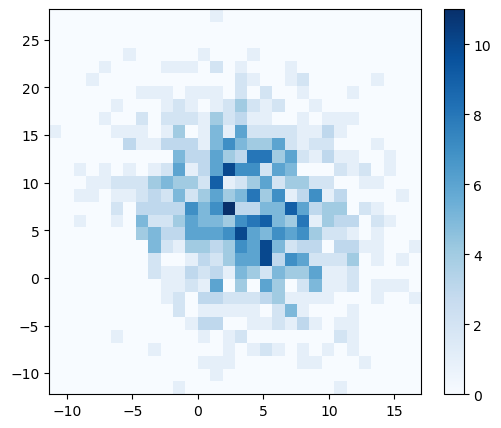

In [43]:
def box_muller_polar(n=1000):
    res = []
    while len(res) < n:
        u, v = np.random.uniform(-1, 1, 2)
        s = u**2 + v**2
        if 0 < s <= 1:
            mult = np.sqrt(-2 * np.log(s) / s)
            res.append([u*mult, v*mult])
    return np.array(res)

z = box_muller_polar()
mu = np.array([4, 7])
Sigma = np.array([[20, -4], [-4, 40]])
L = np.linalg.cholesky(Sigma)
x_mvn = mu + z @ L.T

plt.figure(figsize=(6,5))
plt.hist2d(x_mvn[:,0], x_mvn[:,1], bins=30, cmap='Blues')
plt.colorbar()
plt.show()


### Задача 10*: Случайные разбиения

In [ ]:
bell = [1]
for n in range(100):
    bell.append(sum(math.comb(n, k) * bell[k] for k in range(n + 1)))

def generate_partition(elements):
    n = len(elements)
    if n == 0: return []
    weights = [math.comb(n-1, s-1) * bell[n-s] for s in range(1, n+1)]
    
    probs = np.array(weights, dtype=np.float64)
    probs /= probs.sum()
    s = np.random.choice(np.arange(1, n+1), p=probs)
    
    indices = np.random.choice(n-1, size=s-1, replace=False)
    others = elements[:-1]
    subset = [others[i] for i in indices] + [elements[-1]]
    remaining = [x for i, x in enumerate(others) if i not in indices]
    return [subset] + generate_partition(remaining)

avg_len = np.mean([len(generate_partition(list(range(100)))) for _ in range(100)])
print(f'Estimated subsets for n=100: {avg_len}')
